<a href="https://colab.research.google.com/github/ThomasAlbin/Space-Science-With-Python/blob/main/2026/kirkwood_gaps.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Kirkwood Gaps: Jupiter's Fingerprint in the Asteroid Belt

Asteroids are not spread evenly through the main belt. If we count how many of them orbit at each distance from the Sun, we find striking *gaps*: the **Kirkwood gaps**, noticed by Daniel Kirkwood back in 1866, when fewer than 100 asteroids were known.

The gaps sit where an asteroid's orbital period is a simple fraction of Jupiter's. An asteroid in a **3:1 resonance** orbits the Sun three times while Jupiter orbits once, so Jupiter tugs on it at the same place in its orbit again and again, and these tiny kicks add up.

Kepler's third law, $P^2 \propto a^3$, tells us exactly where these resonances are. If an asteroid makes $p$ orbits while Jupiter makes $q$ orbits, then $P_{ast}/P_J = q/p$ and therefore

$$a = a_J \left(\frac{q}{p}\right)^{2/3}, \qquad a_J \approx 5.2026\,\mathrm{AU}$$

Do real asteroids avoid these distances? Let's check with the JPL Small-Body Database!

In [1]:
import json

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

plt.style.use('dark_background')
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = 11

## Where Should the Gaps Be?

We turn the equation into a function and compute the five classic Kirkwood gaps (4:1, 3:1, 5:2, 7:3, 2:1). We add the 3:2 resonance as well: that is where the Hilda asteroids live.

In [2]:
a_jupiter = 5.2026  # Jupiter's semi-major axis in AU


def resonance_location(p, q):
    """Semi-major axis (AU) of the p:q resonance with Jupiter (asteroid: p orbits, Jupiter: q orbits)."""
    return a_jupiter * (q / p) ** (2 / 3)


resonances = [(4, 1), (3, 1), (5, 2), (7, 3), (2, 1), (3, 2)]

for p, q in resonances:
    print(f"{p}:{q} resonance at a = {resonance_location(p, q):.2f} AU")

4:1 resonance at a = 2.06 AU
3:1 resonance at a = 2.50 AU
5:2 resonance at a = 2.82 AU
7:3 resonance at a = 2.96 AU
2:1 resonance at a = 3.28 AU
3:2 resonance at a = 3.97 AU


## Download the Data

We use the SBDB Query API of JPL to download the semi-major axes of all numbered asteroids (their orbits are well determined) between 1.8 and 4.2 AU.

JPL splits the belt into orbit classes, and the class `MBA` alone covers only 2.0 to 3.2 AU. We add the inner (`IMB`) and outer (`OMB`) belt to cover the whole range.

In [3]:
url = "https://ssd-api.jpl.nasa.gov/sbdb_query.api"
params = {
    "fields": "a",                                      # semi-major axis in AU
    "sb-kind": "a",                                     # asteroids only
    "sb-class": "IMB,MBA,OMB",                          # inner, middle and outer main belt
    "sb-ns": "n",                                       # numbered asteroids only
    "sb-cdata": json.dumps({"AND": ["a|RG|1.8|4.2"]}),  # 1.8 AU <= a <= 4.2 AU
}

print("Downloading data from JPL... (this can take 20-30 seconds)")
response = requests.get(url, params=params, timeout=300)
response.raise_for_status()

df = pd.DataFrame(response.json()["data"], columns=["a"]).astype(float)
print(f"Downloaded {len(df):,} asteroids")

Downloaded 870,825 asteroids


## Visualisation

We count the asteroids in bins of 0.005 AU and overlay the predicted resonance positions. Do the gaps show up where Kepler's third law says they should?

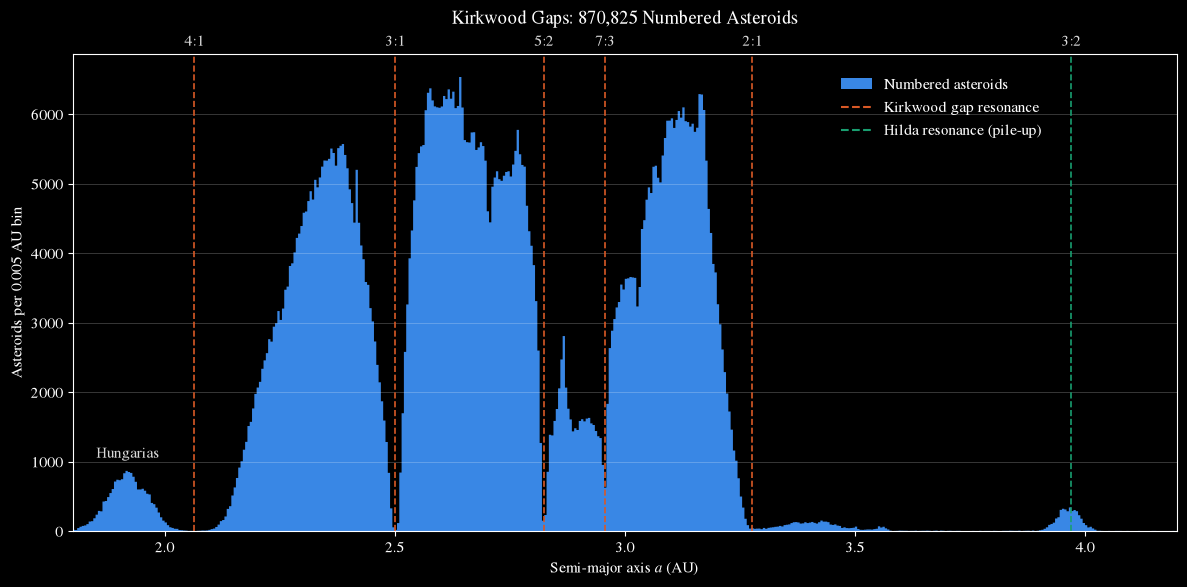

In [4]:
bins = np.arange(1.8, 4.2 + 0.005, 0.005)
gap_color, hilda_color = '#d95926', '#199e70'

fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(df["a"], bins=bins, color='#3987e5', histtype='stepfilled', label="Numbered asteroids")

# Predicted resonance positions (the Hildas are a pile-up, not a gap: different colour)
for p, q in resonances:
    a_res = resonance_location(p, q)
    color = hilda_color if (p, q) == (3, 2) else gap_color
    ax.axvline(a_res, color=color, lw=1.2, ls='--')
    ax.text(a_res, 1.01, f"{p}:{q}", transform=ax.get_xaxis_transform(),
            ha='center', va='bottom', color='0.85')

ax.text(1.92, 1000, "Hungarias", ha='center', va='bottom', color='0.85')

# Empty plots, only used for the legend
ax.plot([], [], color=gap_color, ls='--', label="Kirkwood gap resonance")
ax.plot([], [], color=hilda_color, ls='--', label="Hilda resonance (pile-up)")

ax.set_xlim(1.8, 4.2)
ax.set_xlabel("Semi-major axis $a$ (AU)")
ax.set_ylabel("Asteroids per 0.005 AU bin")
ax.set_title(f"Kirkwood Gaps: {len(df):,} Numbered Asteroids", pad=22)
ax.grid(axis='y', lw=0.5, alpha=0.3)
ax.legend(loc='upper right', bbox_to_anchor=(0.89, 0.98), frameon=False)

plt.tight_layout()
plt.show()

## Take-Aways

* **Kepler's third law predicts the gaps:** $a = a_J (q/p)^{2/3}$ lands right on the depleted regions: clean gaps at 2.50 (3:1) and 2.82 AU (5:2), a narrower dip at 2.96 AU (7:3), the valley at 2.06 AU (4:1) that separates the small group of Hungarias from the inner belt, and the outer edge of the dense belt at 3.28 AU (2:1).
* **Why a gap?** Jupiter's repeated tugs at the same orbital position can pump up an asteroid's eccentricity until it crosses the orbit of Mars and gets scattered away. These gaps are therefore also a supply route for near-Earth asteroids and meteorites.
* **Not every resonance is a gap:** at 3:2 the Hilda asteroids are protected by the resonance and pile up instead.
* **The spikes are not resonances:** they are collisional families, the debris of past asteroid break-ups (for example Eos near 3.0 AU and Themis near 3.1 AU).